# House Sales Analysis and Price Prediction

## Project Overview

This project explores residential property sales data from King County, Washington, to identify factors associated with house prices and build machine learning models for price prediction.

## Objectives

- Explore and understand the housing dataset.
- Clean and prepare data for analysis.
- Perform exploratory data analysis to identify patterns and relationships.
- Build linear and polynomial regression models.
- Apply Ridge regression to reduce overfitting.
- Evaluate and compare model performance.

## Tools and Technologies

- **Language:** Python
- **Libraries:** Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn
- **Environment:** Jupyter Notebook / VS Code

## Dataset

The dataset contains residential property sales from King County, Washington, between May 2014 and May 2015. It includes features such as living area, number of bedrooms, bathrooms, floors, and other property characteristics.

## Project Workflow

1. Data loading and inspection
2. Data cleaning and preparation
3. Exploratory data analysis
4. Feature selection and model development
5. Linear regression
6. Polynomial regression
7. Ridge regression
8. Model evaluation and comparison


## Table of Contents

1. [Project Overview](#project-overview)
2. [About the Dataset](#about-the-dataset)
3. [Loading the Dataset](#loading-the-dataset)
4. [Data Cleaning and Preparation](#data-cleaning-and-preparation)
5. [Exploratory Data Analysis](#exploratory-data-analysis)
6. [Building Regression Models](#building-regression-models)
7. [Model Evaluation and Refinement](#model-evaluation-and-refinement)
8. [Conclusion](#conclusion)


## About the Dataset

This project uses residential property sales data from King County, Washington, which includes Seattle. The dataset covers homes sold between May 2014 and May 2015.

The dataset was originally sourced from [Kaggle – House Sales in King County, USA](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction) and was modified for educational purposes.

### Dataset Features

| Variable | Description |
|---|---|
| `id` | Unique identifier for a house |
| `date` | Date the house was sold |
| `price` | Sale price of the house; target variable |
| `bedrooms` | Number of bedrooms |
| `bathrooms` | Number of bathrooms |
| `sqft_living` | Interior living area in square feet |
| `sqft_lot` | Total lot area in square feet |
| `floors` | Number of floors |
| `waterfront` | Indicates whether the property has a waterfront view |
| `view` | Indicates the property's view rating |
| `condition` | Overall condition of the house |
| `grade` | Overall construction and design quality grade |
| `sqft_above` | Living area above ground level |
| `sqft_basement` | Basement area in square feet |
| `yr_built` | Year the house was built |
| `yr_renovated` | Year the house was renovated, if applicable |
| `zipcode` | Property ZIP code |
| `lat` | Latitude coordinate |
| `long` | Longitude coordinate |
| `sqft_living15` | Average living area of nearby properties in 2015 |
| `sqft_lot15` | Average lot area of nearby properties in 2015 |

### Project Goal

Analyze the dataset to understand the factors associated with residential property prices and develop regression models to predict house sale prices.

## Import the required libraries


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import LinearRegression
%matplotlib inline

## Loading the Dataset

Load the house sales dataset into a Pandas DataFrame for data exploration, cleaning, and analysis.

In [2]:
#import pandas as pd
file_name = "kc_house_data.csv"
# Load the dataset from a CSV file
df = pd.read_csv(file_name)

**Note:** The dataset is loaded locally in this notebook using Pandas. The CSV file must be available in the project directory.

### Preview the Dataset

Display the first five rows to inspect the dataset's structure and sample values.


In [3]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


### Understanding Data Types

Inspect the data type of each column to understand how the dataset's variables are stored.

In [4]:
df.dtypes

id                 int64
date                 str
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

### Descriptive Statistics

Use descriptive statistics to summarize the numerical variables, including their count, mean, standard deviation, minimum, maximum, and quartiles.


In [5]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


## Data Cleaning and Preparation

Prepare the dataset for analysis by removing unnecessary columns, examining descriptive statistics, and handling missing values.


### Descriptive Statistics and Data Cleaning

Generate descriptive statistics for the dataset and remove unnecessary identifier columns. Identify missing values and handle them appropriately to prepare the data for modeling.

In [6]:
df.drop(['id', 'Unnamed: 0'], axis=1, inplace=True, errors='ignore')
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


### Handling Missing Values

Examine missing values in the `bedrooms` and `bathrooms` columns. Replace missing entries with the respective column means to retain these records for further analysis.


In [7]:
print("number of NaN values for the column bedrooms :", df['bedrooms'].isnull().sum())
print("number of NaN values for the column bathrooms :", df['bathrooms'].isnull().sum())


number of NaN values for the column bedrooms : 0
number of NaN values for the column bathrooms : 0


In [8]:
mean = df['bedrooms'].mean()
df['bedrooms'] = df['bedrooms'].replace(np.nan, mean)

In [9]:
mean = df['bathrooms'].mean()
df['bathrooms'] = df['bathrooms'].replace(np.nan, mean)

In [10]:
print("number of NaN values for the column bedrooms :", df['bedrooms'].isnull().sum())
print("number of NaN values for the column bathrooms :", df['bathrooms'].isnull().sum())

number of NaN values for the column bedrooms : 0
number of NaN values for the column bathrooms : 0


## Exploratory Data Analysis

Explore the distribution of property characteristics and investigate how selected features relate to house prices using statistical summaries and visualizations.


### Distribution of Houses by Number of Floors

Count the number of properties for each distinct floor value and present the results in a DataFrame. 


In [11]:
df["floors"].value_counts().to_frame()

,count
floors,
1.0,10680
2.0,8241
1.5,1910
3.0,613
2.5,161
3.5,8


### House Price Outliers by Waterfront View

Use boxplots to compare house prices for properties with and without waterfront views and examine differences in their price distributions and potential outliers.


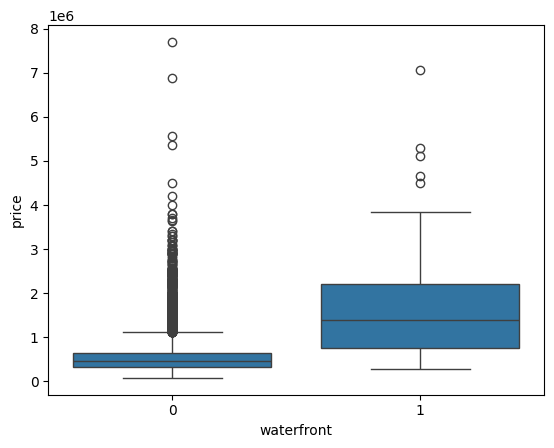

In [12]:
sns.boxplot(x="waterfront", y="price", data=df)
plt.show()

### Correlation Analysis

Use a regression plot to examine the relationship between the above-ground living area (`sqft_above`) and house prices (`price`). Determine whether the relationship is positive or negative.

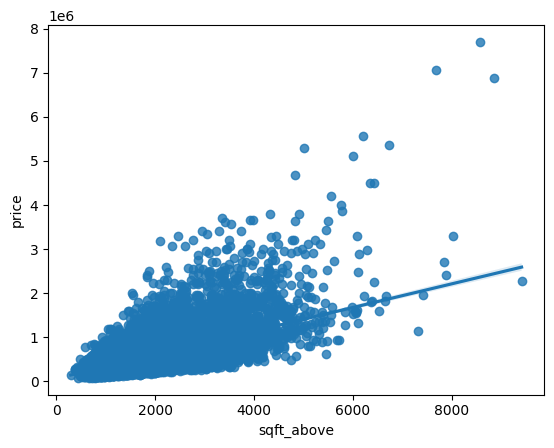

In [13]:
sns.regplot(x="sqft_above", y="price", data=df)
plt.show()

Identify the property feature most strongly correlated with house price by examining the correlation matrix.

In [14]:
df_numeric = df.select_dtypes(include=[np.number])
df_numeric.corr()['price'].sort_values()

zipcode         -0.053203
long             0.021626
condition        0.036362
yr_built         0.054012
sqft_lot15       0.082447
sqft_lot         0.089661
yr_renovated     0.126434
floors           0.256794
waterfront       0.266369
lat              0.307003
bedrooms         0.308350
sqft_basement    0.323816
view             0.397293
bathrooms        0.525138
sqft_living15    0.585379
sqft_above       0.605567
grade            0.667434
sqft_living      0.702035
price            1.000000
Name: price, dtype: float64

## Building Regression Models

Develop linear regression models to predict residential property prices using individual features and multiple property characteristics.


### Baseline Model Using Longitude

Fit a linear regression model using longitude (`long`) as the predictor and evaluate its performance using the coefficient of determination (R²).

In [15]:
X = df[['long']]
Y = df['price']
lm = LinearRegression()
lm.fit(X,Y)
lm.score(X, Y)

0.0004676943014898516

### Predicting Prices Using Living Area

Build a linear regression model using living area (`sqft_living`) to predict house prices. Evaluate the model using R² to measure how well it explains variations in sale prices.

In [16]:
X = df[['sqft_living']]
Y = df['price']
lm = LinearRegression()
lm.fit(X,Y)
R_squared = lm.score(X, Y)
print("R^2:", R_squared)

R^2: 0.4928532179037931


### Multiple Linear Regression

Build a linear regression model using multiple property features to predict house sale prices and evaluate its performance.

Evaluate the multiple linear regression model using the coefficient of determination (R²) to assess its predictive performance.

In [17]:
features = ["floors", "waterfront", "lat", "bedrooms", "sqft_basement",
            "view", "bathrooms", "sqft_living15", "sqft_above",
            "grade", "sqft_living"]
X = df[features]
Y = df["price"]
lm = LinearRegression()
lm.fit(X, Y)
R_squared = lm.score(X, Y)
print("R^2:", R_squared)

R^2: 0.6577151058279322


### Preparing the Regression Pipeline

Define a machine learning pipeline that standardizes the input features, generates polynomial features, and fits a linear regression model.


### Polynomial Regression Pipeline

Create a machine learning pipeline using feature scaling, polynomial feature transformation, and linear regression. Fit the pipeline using the selected features and evaluate its performance using R².

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression

Input = [
    ('scale', StandardScaler()),
    ('polynomial', PolynomialFeatures(include_bias=False)),
    ('model', LinearRegression())
]

pipe = Pipeline(Input)

X = df[features]
Y = df['price']

pipe.fit(X, Y)

R_squared = pipe.score(X, Y)

print("R^2:", R_squared)

R^2: 0.7513467656307783


## Model Evaluation and Refinement

Evaluate regression models using training and testing datasets. Apply regularization and polynomial transformations to examine their impact on predictive performance.


Import the necessary modules:


In [19]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
print("done")

done


### Training and Testing Data

Split the dataset into training and testing sets to evaluate how well the models perform on unseen data.


In [20]:
features =["floors", "waterfront","lat" ,"bedrooms" ,"sqft_basement" ,"view" ,"bathrooms","sqft_living15","sqft_above","grade","sqft_living"]    
X = df[features]
Y = df['price']

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.15, random_state=1)


print("number of test samples:", x_test.shape[0])
print("number of training samples:",x_train.shape[0])

number of test samples: 3242
number of training samples: 18371


### Ridge Regression

Train a Ridge regression model with a regularization parameter of 0.1. Evaluate the model using the test dataset and the R² score.

In [21]:
from sklearn.linear_model import Ridge

In [22]:
RidgeModel = Ridge(alpha=0.1)
RidgeModel.fit(x_train, y_train)
R_squared = RidgeModel.score(x_test, y_test)
print("R^2:", R_squared)

R^2: 0.6480374087702245


### Polynomial Ridge Regression

Transform the training and testing features into second-degree polynomial features. Fit a Ridge regression model with a regularization parameter of 0.1 using the transformed training data, then evaluate its performance on the transformed test data using R².

In [23]:
pr = PolynomialFeatures(degree=2)
x_train_pr = pr.fit_transform(x_train)
x_test_pr = pr.transform(x_test)
RidgeModel = Ridge(alpha=0.1)
RidgeModel.fit(x_train_pr, y_train)
R_squared = RidgeModel.score(x_test_pr, y_test)
print("R^2:", R_squared)

R^2: 0.7004432049713085


## Conclusion

This project explored residential property sales data from King County, Washington, to understand the factors associated with house prices.

The analysis covered data inspection, data cleaning, exploratory data analysis, and regression modeling. Linear regression, polynomial regression, and Ridge regression were used to explore different approaches to price prediction.

The models were evaluated using the R² score. The test-set results from Ridge regression and Polynomial Ridge regression can help assess how well the models predict prices for unseen properties.

Overall, the project demonstrates how Python and machine learning techniques can be used to analyze housing data and build price prediction models.